# Emotion Detection on News

### Description of the data used, extraced from [Zenodo](https://zenodo.org/records/7976208):

This dataset contains news headlines relevant to key forex pairs: AUDUSD, EURCHF, EURUSD, GBPUSD, and USDJPY. The data was extracted from reputable platforms Forex Live and FXstreet over a period of 86 days, from January to May 2023.

The dataset comprises 2,291 unique news headlines. Each headline includes an associated forex pair, timestamp, source, author, URL, and the corresponding article text.

Data was collected using web scraping techniques executed via a custom service on a virtual machine. This service periodically retrieves the latest news for a specified forex pair (ticker) from each platform, parsing all available information. The collected data is then processed to extract details such as the article's timestamp, author, and URL. The URL is further used to retrieve the full text of each article.

## Data cleaning and preprocessing

### Prompting Google Drive for access


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Importing libraries


In [ ]:
import pandas as pd
import seaborn as sns
import re
import spacy
import matplotlib.pyplot as plt
from textblob import TextBlob

### Loading data

In [ ]:
news_df = pd.read_csv('/content/drive/MyDrive/sentiment_annotated_with_texts.csv')
news_df.head()

,published_at,ticker,true_sentiment,title,author,url,source,text,finbert_sentiment,finbert_sent_score
0,2023-01-12 07:47:00,EURCHF,Positive,Euro to benefit from the ECBs pronounced hawki...,FXStreet Insights Team,https://www.fxstreet.com/news/euro-to-benefit-...,FX Street,The Euro was able to appreciate particularly s...,Positive,0.85
1,2023-01-12 10:34:00,EURCHF,Positive,EURCHF Trend higher may remain in place – ING,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-trend-hi...,FX Street,EUR/CHF yesterday broke above 1.00. Economists...,Positive,0.51
2,2023-01-12 11:40:00,EURCHF,Neutral,Does a jump in EURCHF point to a break above 1...,FXStreet Insights Team,https://www.fxstreet.com/news/does-a-jump-in-e...,FX Street,EUR/CHF vaults parity for the first time since...,Neutral,0.37
3,2023-01-12 15:32:00,EURCHF,Positive,EURCHF could extend its advance back to levels...,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-could-ex...,FX Street,EUR/CHF climbs back above parity. Economists a...,Positive,0.64
4,2023-01-13 11:37:00,EURCHF,Positive,EURCHF to head higher towards 10130 and projec...,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-to-head-...,FX Street,EUR/CHF has broken out above the sideways rang...,Positive,0.83


### Statistics and information from uncleaned data

In [ ]:
# Describing the columns
author = news_df['author'].describe()
title = news_df['title'].describe()
true_sentiment = news_df[['true_sentiment']].describe()
finbert_sentiment = news_df[['finbert_sentiment']].describe()
finbert_sent_score = news_df[['finbert_sent_score']].describe()

print("Description of 'author':")
print(author)
print("Description of 'title':")
print(title)
print("Description of 'true_sentiment':")
print(true_sentiment)
print("Description of 'finbert_sentiment':")
print(finbert_sentiment)
print("Description of 'finbert_sent_score':")
print(finbert_sent_score)


Description of 'author':
count                       2291
unique                        18
top       FXStreet Insights Team
freq                         416
Name: author, dtype: object

Description of 'title':
count                          2291
unique                         2265
top       EURUSD Technical Analysis
freq                              7
Name: title, dtype: object

Description of 'true_sentiment':
       true_sentiment
count            2291
unique              3
top           Neutral
freq              815

Description of 'finbert_sentiment':
       finbert_sentiment
count               2291
unique                 3
top             Negative
freq                 871

Description of 'finbert_sent_score':
       finbert_sent_score
count          2291.00000
mean             -0.03151
std               0.60936
min              -0.97000
25%              -0.65000
50%               0.01000
75%               0.49000
max               0.94000


In [ ]:
# Displaying distribution of true_sentiment and finbert_sentiment
sentimentDist = news_df['true_sentiment'].value_counts()
finSentiment = news_df['finbert_sentiment'].value_counts()

print("Value counts of 'true_sentiment':")
print(sentimentDist)
print("Value counts of 'finbert_sentiment':")
print(finSentiment)

Value counts of 'true_sentiment':
Neutral     815
Positive    767
Negative    709
Name: true_sentiment, dtype: int64

Value counts of 'finbert_sentiment':
Negative    871
Positive    797
Neutral     623
Name: finbert_sentiment, dtype: int64


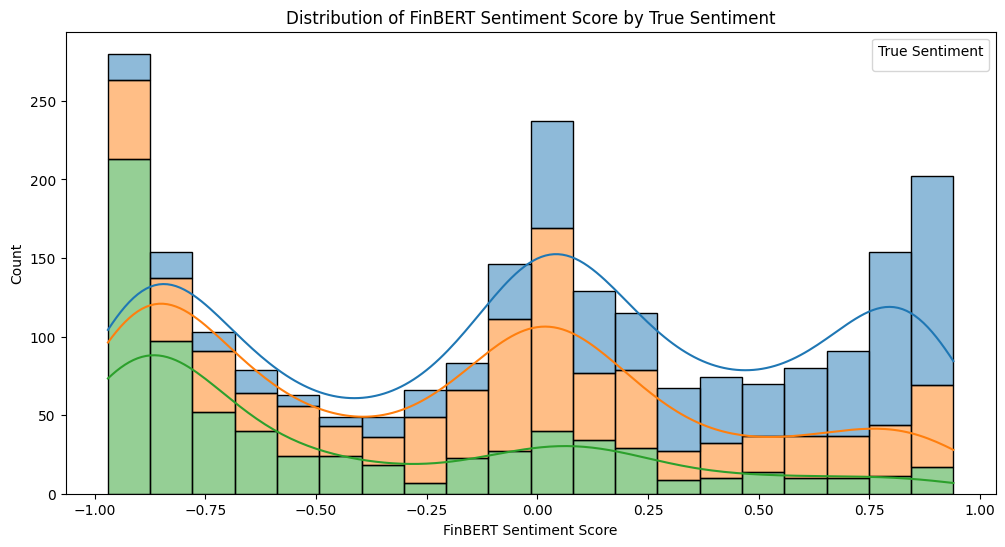

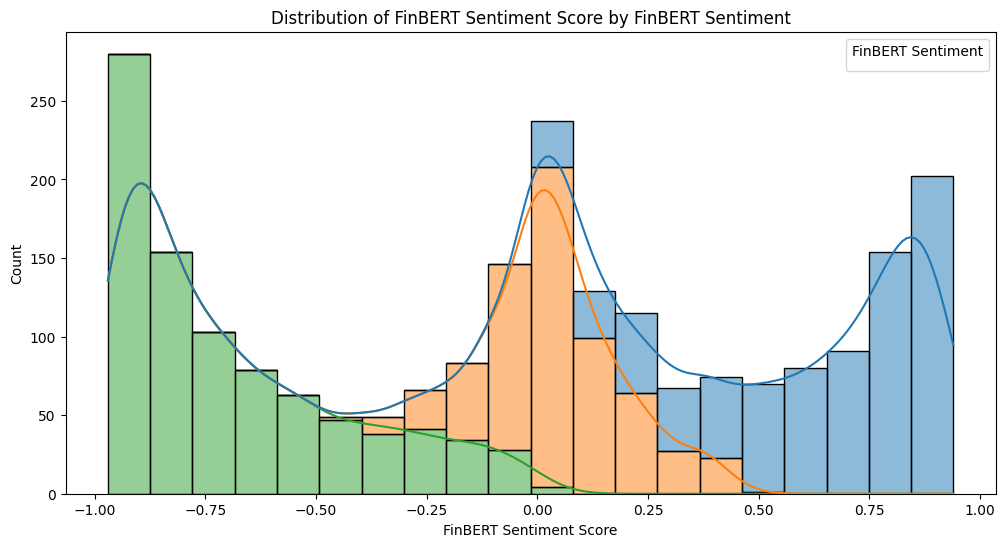


Summary statistics for 'finbert_sent_score' by 'true_sentiment':
                count      mean       std   min    25%   50%   75%   max
true_sentiment                                                          
Negative        709.0 -0.444147  0.540237 -0.97 -0.900 -0.71  0.01  0.93
Neutral         815.0 -0.028282  0.520758 -0.96 -0.395 -0.01  0.27  0.94
Positive        767.0  0.346493  0.501457 -0.95  0.050  0.45  0.80  0.94

Summary statistics for 'finbert_sent_score' by 'finbert_sentiment':
                   count      mean       std   min   25%   50%    75%   max
finbert_sentiment                                                          
Negative           871.0 -0.687566  0.258690 -0.97 -0.90 -0.77 -0.535 -0.00
Neutral            623.0  0.042520  0.157904 -0.43 -0.04  0.04  0.130  0.48
Positive           797.0  0.627591  0.255747  0.00  0.46  0.71  0.850  0.94


In [ ]:
# Summary statistics for 'finbert_sent_score' grouped by 'true_sentiment' and 'finbert_sentiment'
fin_score_summary_by_true = news_df.groupby('true_sentiment')['finbert_sent_score'].describe()
fin_score_summary_by_finbert = news_df.groupby('finbert_sentiment')['finbert_sent_score'].describe()

# Plotting the distributions of 'finbert_sent_score' for 'true_sentiment' and 'finbert_sentiment'
plt.figure(figsize=(12, 6))
sns.histplot(data=news_df, x='finbert_sent_score', hue='true_sentiment', multiple='stack', bins=20, kde=True)
plt.title('Distribution of FinBERT Sentiment Score by True Sentiment')
plt.xlabel('FinBERT Sentiment Score')
plt.ylabel('Count')
plt.legend(title='True Sentiment')
plt.show()

plt.figure(figsize=(12, 6))
sns.histplot(data=news_df, x='finbert_sent_score', hue='finbert_sentiment', multiple='stack', bins=20, kde=True)
plt.title('Distribution of FinBERT Sentiment Score by FinBERT Sentiment')
plt.xlabel('FinBERT Sentiment Score')
plt.ylabel('Count')
plt.legend(title='FinBERT Sentiment')
plt.show()

# Displaying value counts and summary statistics
print("\nSummary statistics for 'finbert_sent_score' by 'true_sentiment':")
print(fin_score_summary_by_true)
print("\nSummary statistics for 'finbert_sent_score' by 'finbert_sentiment':")
print(fin_score_summary_by_finbert)

### Data cleaning

In [ ]:
# Handling missing values
news_df.fillna('', inplace=True)

# Removing duplicate rows
news_df = news_df.drop_duplicates()

# Converting to lowercase
news_df['title'] = news_df['title'].str.lower()
news_df['text'] = news_df['text'].str.lower()

# Removing punctuation
news_df['title'] = news_df['title'].apply(lambda x: re.sub(r'[^\w\s]', '', x))
news_df['text'] = news_df['text'].apply(lambda x: re.sub(r'[^\w\s]', '', x))

# Removing titles with less than 3 word, texts with less than 50 words
news_df = news_df[news_df['title'].apply(lambda x: len(x.split()) >= 3)]
news_df = news_df[news_df['text'].apply(lambda x: len(x.split()) >= 50)]

## Text classification using SpaCy

In [ ]:
nlp = spacy.load("en_core_web_sm")

# Classifiying whether text belongs to a headline or longer news text
def classify_text(text):
    doc = nlp(text)
    return "headline" if len(doc) <= 10 else "news_text"

text_columns = ['title', 'text']

for column in text_columns:
    news_df[column + '_Text_Type'] = news_df[column].apply(classify_text)

### Feature extraction from text

In [ ]:
news_df['TitleLength'] = news_df['title'].apply(len)
news_df['TextLength'] = news_df['text'].apply(len)

print("Title Lengths:", news_df['TitleLength'])
print("Text Lengths:", news_df['TextLength'])

Title Lengths: 0       75
1       44
2       66
3       72
4       73
        ..
2286    74
2287    50
2288    54
2289    81
2290    55
Name: TitleLength, Length: 2274, dtype: int64
Text Lengths: 0        706
1        593
2        739
3        789
4        545
        ... 
2286    1793
2287     538
2288     482
2289     533
2290    1063
Name: TextLength, Length: 2274, dtype: int64


In [ ]:
# Tokenizing and lemmatizing text
def tokenize_and_lemmatize(text):
    doc = nlp(text)
    return [token.lemma_ for token in doc]

news_df['TitleTokens'] = news_df['title'].apply(tokenize_and_lemmatize)
news_df['TextTokens'] = news_df['text'].apply(tokenize_and_lemmatize)

print("Title Tokens:", news_df['TitleTokens'])
print("Text Tokens:"), news_df['TextTokens']

Title Tokens: 0       [euro, to, benefit, from, the, ecbs, pronounce...
1       [eurchf, trend, higher, may, remain, in, place...
2       [do, a, jump, in, eurchf, point, to, a, break,...
3       [eurchf, could, extend, its, advance, back, to...
4       [eurchf, to, head, high, towards, 10130, and, ...
                              ...                        
2286    [gbpusd, hold, steady, near, its, high, level,...
2287    [eurchf, to, break, below, the, 097, level,  ,...
2288    [eurusd, shortterm, dip, likely, support, near...
2289    [gbpusd, look, for, an, eventual, final, leg, ...
2290    [usdjpy, break, below, 13400, as, wall, street...
Name: TitleTokens, Length: 2274, dtype: object
Text Tokens:


(None,
 0       [the, euro, be, able, to, appreciate, particul...
 1       [eurchf, yesterday, break, above, 100, economi...
 2       [eurchf, vault, parity, for, the, first, time,...
 3       [eurchf, climb, back, above, parity, economist...
 4       [eurchf, have, break, out, above, the, sideway...
                               ...                        
 2286    [the, gbpusd, pair, enter, a, bullish, consoli...
 2287    [eurchf, have, turn, back, lower, over, the, p...
 2288    [the, european, central, bank, ecbdownshifte, ...
 2289    [economist, at, credit, suisse, discuss, gbp, ...
 2290    [the, usdjpy, have, break, low, and, tumble, t...
 Name: TextTokens, Length: 2274, dtype: object)

### Sentiment and Emotional Analysis

In [ ]:
def load_lexicon(filepath):
    lexicon = {}
    with open(filepath, 'r') as file:
        for line in file:
            word, valence, arousal, dominance = line.strip().split('\t')
            lexicon[word.lower()] = {'valence': float(valence), 'arousal': float(arousal), 'dominance': float(dominance)}
    return lexicon

lexicon = load_lexicon('/content/drive/MyDrive/NRC-VAD-Lexicon.txt')

In [ ]:
def analyze_emotion(text, dimension):
    scores = [lexicon.get(word.lower(), {}).get(dimension, 0) for word in text.split()]
    return sum(scores) / max(len(scores), 1)

def analyze_valence(text):
    return analyze_emotion(text, 'valence')

def analyze_arousal(text):
    return analyze_emotion(text, 'arousal')

def analyze_dominance(text):
    return analyze_emotion(text, 'dominance')

news_df['TitleValence'] = news_df['title'].apply(analyze_valence)
news_df['TextValence'] = news_df['text'].apply(analyze_valence)

news_df['TitleArousal'] = news_df['title'].apply(analyze_arousal)
news_df['TextArousal'] = news_df['text'].apply(analyze_arousal)

news_df['TitleDominance'] = news_df['title'].apply(analyze_dominance)
news_df['TextDominance'] = news_df['text'].apply(analyze_dominance)

print(news_df[['title', 'text', 'TitleValence', 'TextValence', 'TitleArousal', 'TextArousal', 'TitleDominance', 'TextDominance']].head())

                                               title  \
0  euro to benefit from the ecbs pronounced hawki...   
1       eurchf trend higher may remain in place  ing   
2  does a jump in eurchf point to a break above 1...   
3  eurchf could extend its advance back to levels...   
4  eurchf to head higher towards 10130 and projec...   

                                                text  TitleValence  \
0  the euro was able to appreciate particularly s...      0.303200   
1  eurchf yesterday broke above 100 economists at...      0.434625   
2  eurchf vaults parity for the first time since ...      0.123214   
3  eurchf climbs back above parity economists at ...      0.135154   
4  eurchf has broken out above the sideways range...      0.126909   

   TextValence  TitleArousal  TextArousal  TitleDominance  TextDominance  
0     0.215817      0.213900     0.149101        0.281600       0.196110  
1     0.237586      0.235625     0.154775        0.349125       0.197387  
2     0.197148   

In [ ]:
def analyze_sentiment(text):
    blob = TextBlob(text)
    return blob.sentiment.polarity

news_df['TitleSentiment'] = news_df['title'].apply(analyze_sentiment)
news_df['TextSentiment'] = news_df['text'].apply(analyze_sentiment)

print(news_df[['title', 'text', 'TitleSentiment', 'TextSentiment']].head())

                                               title  \
0  euro to benefit from the ecbs pronounced hawki...   
1       eurchf trend higher may remain in place  ing   
2  does a jump in eurchf point to a break above 1...   
3  eurchf could extend its advance back to levels...   
4  eurchf to head higher towards 10130 and projec...   

                                                text  TitleSentiment  \
0  the euro was able to appreciate particularly s...            0.00   
1  eurchf yesterday broke above 100 economists at...            0.25   
2  eurchf vaults parity for the first time since ...            0.00   
3  eurchf climbs back above parity economists at ...            0.00   
4  eurchf has broken out above the sideways range...            0.25   

   TextSentiment  
0       0.257738  
1       0.016667  
2       0.036786  
3       0.195641  
4       0.033333  


### Visualizing

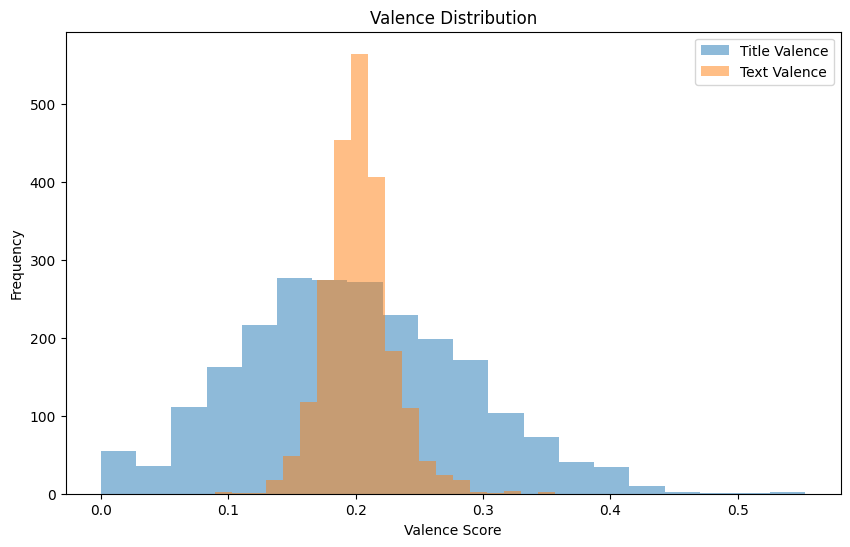

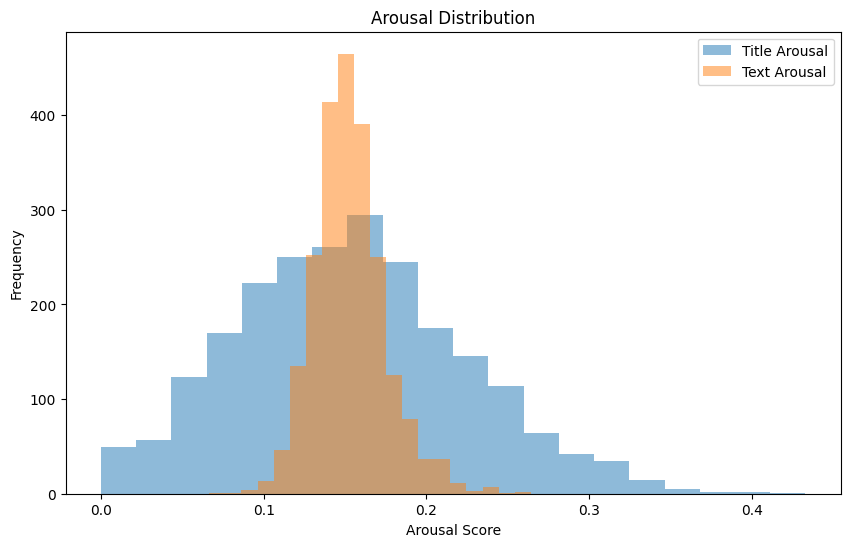

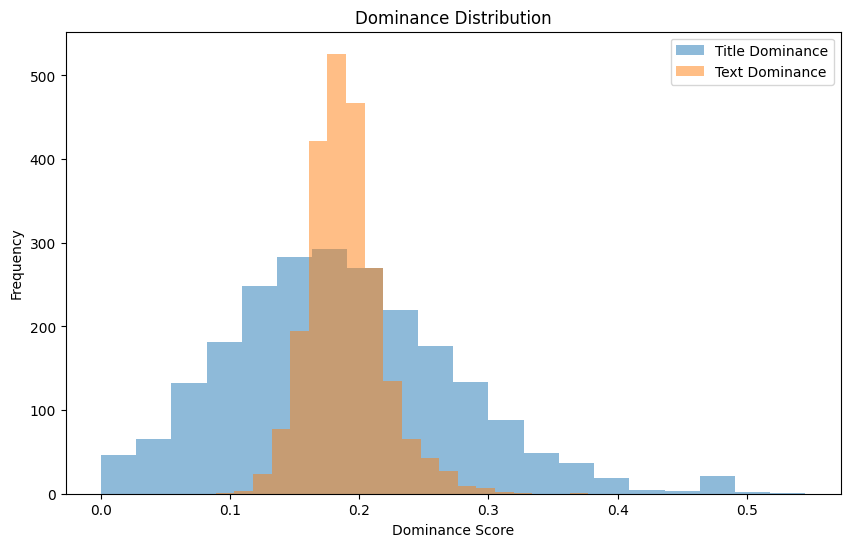

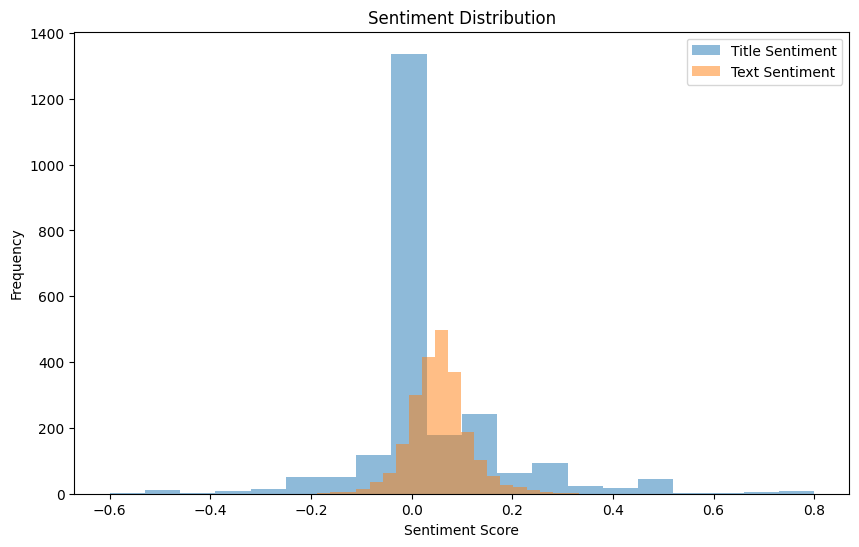

In [ ]:
# Plotting Valence
plt.figure(figsize=(10, 6))
plt.hist(news_df['TitleValence'], bins=20, alpha=0.5, label='Title Valence')
plt.hist(news_df['TextValence'], bins=20, alpha=0.5, label='Text Valence')
plt.title('Valence Distribution')
plt.xlabel('Valence Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# Plotting Arousal
plt.figure(figsize=(10, 6))
plt.hist(news_df['TitleArousal'], bins=20, alpha=0.5, label='Title Arousal')
plt.hist(news_df['TextArousal'], bins=20, alpha=0.5, label='Text Arousal')
plt.title('Arousal Distribution')
plt.xlabel('Arousal Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# Plotting Dominance
plt.figure(figsize=(10, 6))
plt.hist(news_df['TitleDominance'], bins=20, alpha=0.5, label='Title Dominance')
plt.hist(news_df['TextDominance'], bins=20, alpha=0.5, label='Text Dominance')
plt.title('Dominance Distribution')
plt.xlabel('Dominance Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# Plotting Sentiment
plt.figure(figsize=(10, 6))
plt.hist(news_df['TitleSentiment'], bins=20, alpha=0.5, label='Title Sentiment')
plt.hist(news_df['TextSentiment'], bins=20, alpha=0.5, label='Text Sentiment')
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()